In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [4]:
train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (60000, 785)
Testing data shape: (10000, 785)


In [ ]:
# Separate Features and Labels

In [5]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [6]:
# Normalize Pixel Values

In [7]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [8]:
# Reshape Images

In [9]:
X_train = X_train.reshape(-1, 28, 28)
X_test = X_test.reshape(-1, 28, 28)

In [10]:
# Build FNN with Two Hidden Dense Layers

In [11]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
# Compile Model

In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Train Model

In [16]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8993 - loss: 0.3565 - val_accuracy: 0.9562 - val_loss: 0.1530
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9571 - loss: 0.1469 - val_accuracy: 0.9635 - val_loss: 0.1270
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9693 - loss: 0.1007 - val_accuracy: 0.9708 - val_loss: 0.0980
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9766 - loss: 0.0771 - val_accuracy: 0.9743 - val_loss: 0.0866
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9817 - loss: 0.0599 - val_accuracy: 0.9773 - val_loss: 0.0782
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9854 - loss: 0.0483 - val_accuracy: 0.9763 - val_loss: 0.0793
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9885 - loss: 0.0385 - val_accuracy: 0.9760 - val_loss: 0.0846
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9900 - loss: 0.0333 - val_accu

In [17]:
#evaluate Testing Accuracy

In [19]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", test_loss)
print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9768 - loss: 0.0794
Testing Loss: 0.07941911369562149
Testing Accuracy: 97.680002450943 %


In [20]:
# Plot Accuracy Graph

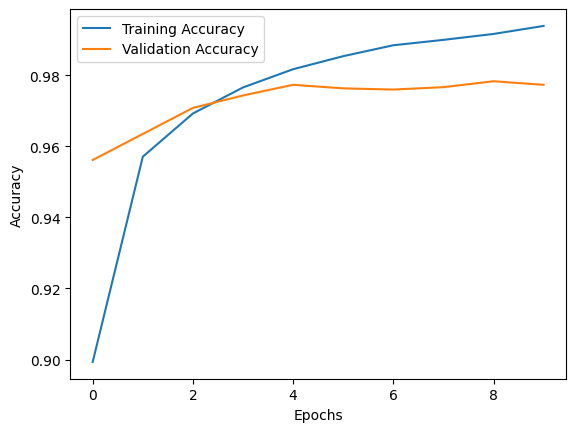

In [21]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [22]:
# Plot Loss Graph

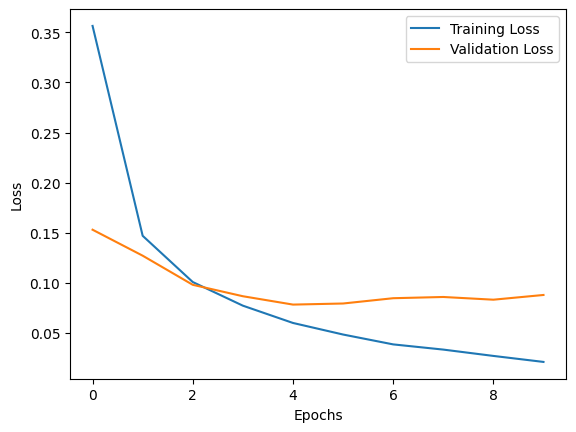

In [23]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [24]:
# Predict Five Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step


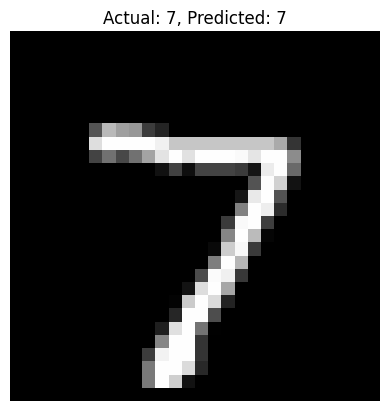

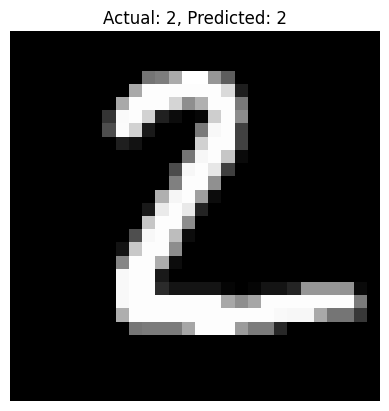

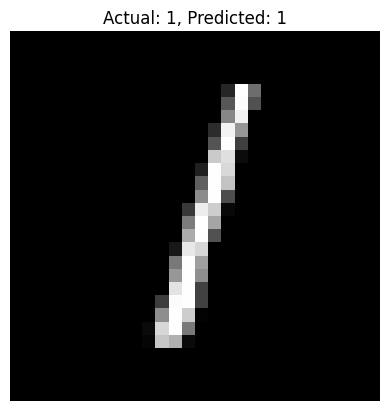

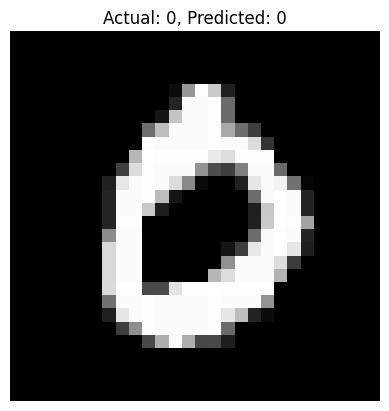

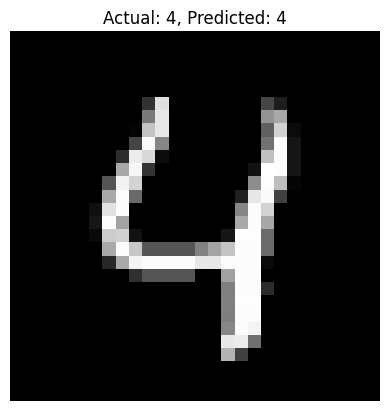

In [25]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

for i in range(5):
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"Actual: {y_test[i]}, Predicted: {predicted_labels[i]}")
    plt.axis('off')
    plt.show()

Here are **25 important code-based viva questions with answers** covering both Practical 12 and Practical 15 (FNN using Handwritten MNIST).

## FNN – Handwritten MNIST: 25 Viva Questions

**1. Which function is used to load the MNIST dataset?**  
`mnist.load_data()` – It loads handwritten digit images.

**2. What is the MNIST dataset?**  
It is a dataset of handwritten digits from 0 to 9.

**3. How many images are present in the MNIST training dataset?**  
60,000 images.

**4. How many images are present in the MNIST testing dataset?**  
10,000 images.

**5. What is the size of each MNIST image?**  
28 × 28 pixels.

**6. What does `X_train` contain?**  
It contains training images.

**7. What does `y_train` contain?**  
It contains the actual digit labels (0–9).

**8. Why do we divide pixel values by 255?**  
To normalize pixel values from 0–255 to 0–1.

**9. What is the purpose of `Flatten()`?**  
It converts a 2D image (28 × 28) into a 1D array of 784 values.

**10. What is the purpose of `Sequential()`?**  
It creates a neural network by adding layers one after another.

**11. What is a Dense layer?**  
A fully connected layer in which each neuron connects to all neurons in the previous layer.

**12. What does `Dense(128, activation='relu')` mean?**  
It creates a hidden layer containing 128 neurons with ReLU activation.

**13. What is ReLU activation?**  
ReLU converts negative values into zero and keeps positive values unchanged.

**14. Why do we use two hidden Dense layers in Practical 15?**  
To observe how adding another hidden layer affects the model's learning and performance.

**15. What is the difference between one and two hidden layers?**  
Two hidden layers can learn more complex patterns, but they may also require more training.

**16. Why do we use `Dense(10, activation='softmax')`?**  
Because MNIST has 10 output classes (digits 0–9). Softmax gives probabilities for each class.

**17. What is the purpose of `model.compile()`?**  
It configures the model using an optimizer, loss function and evaluation metric.

**18. Which optimizer is commonly used in this practical?**  
Adam optimizer. It updates model weights to reduce errors.

**19. Which loss function is used for MNIST classification?**  
Sparse categorical crossentropy.

**20. Why do we use `metrics=['accuracy']`?**  
To measure the percentage of correctly classified images.

**21. What is the purpose of `model.fit()`?**  
It trains the model using training images and their labels.

**22. What is an epoch?**  
One complete pass through the entire training dataset.

**23. What is the purpose of `model.evaluate(X_test, y_test)`?**  
It evaluates the trained model on testing data and returns test loss and accuracy.

**24. What is the purpose of `model.predict()`?**  
It predicts the output probabilities for new or unseen images.

**25. What does `np.argmax(prediction)` do?**  
It returns the index of the highest probability, which represents the predicted digit.

---

### Important code statements to remember

| Code | Purpose |
|---|---|
| `mnist.load_data()` | Loads MNIST dataset |
| `X_train / 255.0` | Normalizes images |
| `Flatten()` | Converts image into 784 values |
| `Dense(128, activation='relu')` | Creates hidden layer |
| `Dense(10, activation='softmax')` | Creates output layer |
| `model.compile()` | Configures model |
| `model.fit()` | Trains model |
| `model.evaluate()` | Tests model performance |

**Important for Practical 15:** Be ready to explain why you added a second hidden Dense layer and compare its accuracy with the one-hidden-layer model.